# 相場の指数と、延ばす速さの決め方（fujise）

PR #35 の `src/target.py` で作る相場の指数（価格帯ごと）を点で描き、傾きを決める期間（直近 4 四半期・直近 8 四半期・2022 年以降・全期間）ごとに、当てはめた直線と、テスト期間への延ばし方を重ねる。

- 実線：その期間に当てはめた直線
- 破線：テスト期間への延ばし方。`Trend.log_index` と同じく、一番新しい四半期の指数（0）から傾きで延ばす
- 灰色の帯：テスト期間（2025Q3〜2026Q1）

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401  グラフで日本語を表示する
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src import preprocess, selection, target, validation


## 設定

`DATA` を `"fold0"` にすると、CV の fold 0 の学習データ（〜2024Q3）で作った指数になる。`"本番"` は学習データ全体（〜2025Q2）で、提出に使う指数と同じ。

In [ ]:
DATA = "本番"  # "本番" または "fold0"

# 傾きを決める期間。値は「一番新しい四半期から何四半期さかのぼるか」（None は全期間）
WINDOWS = {
    "直近 4 四半期（今）": 4,
    "直近 8 四半期": 8,
    "2022 年以降": "2022",
    "全期間": None,
}
# 検証済みの 4 色（dataviz の categorical 1〜4。CVD の差 ΔE ≥ 9）
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
FIRST_QUARTER_2022 = 12  # 経過四半期は 2019Q1 が 0
TEST_LAST_QUARTER = 28  # 2026Q1


In [ ]:
df = preprocess.load()
train = df[df["is_train"]].reset_index(drop=True)
if DATA == "fold0":
    train = train.iloc[validation.time_series_folds(train)[0][0]]
tr, _ = selection.select(train)

trend = target.fit_trend(tr)
last = trend.last_quarter
groups = ["全体", "1", "2", "3", "4", "5"]
titles = {
    "全体": "全体",
    "1": "価格帯 1（安い）",
    "2": "価格帯 2",
    "3": "価格帯 3",
    "4": "価格帯 4",
    "5": "価格帯 5（高い）",
}


def window_points(level: pd.Series, window) -> pd.Series:
    """傾きを当てはめる点を返す。"""
    if window is None:
        return level
    if window == "2022":
        return level[level.index >= FIRST_QUARTER_2022]
    return level[level.index > level.index.max() - window]


def quarter_label(q: int) -> str:
    return f"{2019 + q // 4}Q{q % 4 + 1}"


## 価格帯ごとの指数と、期間ごとの直線

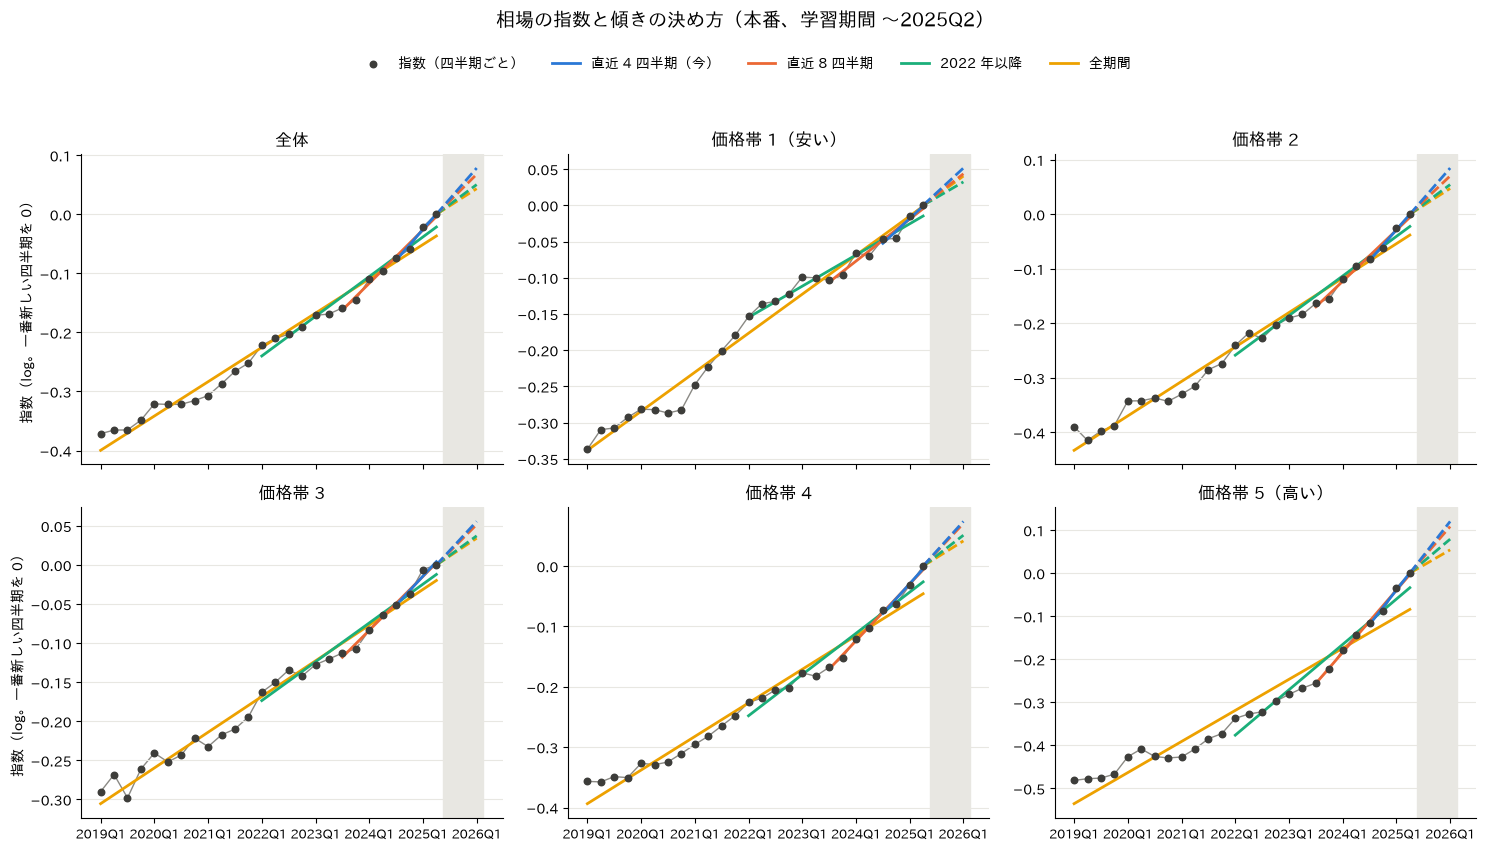

In [ ]:
def draw(x_from: int, title: str) -> None:
    """価格帯ごとに、指数の点と期間ごとの直線を描く。x_from より前は描かない。"""
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True)
    n = len(WINDOWS)
    for ax, g in zip(axes.flat, groups, strict=True):
        level = trend.level[g]
        shown = level[level.index >= x_from]
        ax.axvspan(last + 0.5, TEST_LAST_QUARTER + 0.5, color="#e8e7e2", zorder=0)
        ax.plot(shown.index, shown.to_numpy(), color="#8a8984", linewidth=1, zorder=1)
        ax.scatter(
            shown.index,
            shown.to_numpy(),
            s=22,
            color="#3d3d3a",
            zorder=10,
            label="指数（四半期ごと）",
        )
        for i, ((name, window), color) in enumerate(
            zip(WINDOWS.items(), COLORS, strict=True)
        ):
            pts = window_points(level, window)
            a, b = np.polyfit(pts.index, pts.to_numpy(), 1)
            # 短い期間の線ほど上に重ねる（長い期間の線に隠れないように）
            z = 3 + n - i
            x = np.array([max(pts.index.min(), x_from), pts.index.max()])
            ax.plot(x, a * x + b, color=color, linewidth=2, zorder=z, label=name)
            xf = np.array([last, TEST_LAST_QUARTER])
            ax.plot(
                xf, a * (xf - last), color=color, linewidth=2, linestyle="--", zorder=z
            )
        ax.set_title(titles[g], fontsize=12)
        ax.grid(axis="y", color="#e8e7e2", linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        step = 4 if x_from == 0 else 2
        ticks = list(range(x_from, TEST_LAST_QUARTER + 1, step))
        ax.set_xticks(ticks, [quarter_label(q) for q in ticks], fontsize=9)
    for ax in axes[:, 0]:
        ax.set_ylabel("指数（log。一番新しい四半期を 0）")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.suptitle(title, y=0.995, fontsize=14)
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.955),
        ncol=5,
        frameon=False,
        fontsize=10,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    plt.show()


draw(0, f"相場の指数と傾きの決め方（{DATA}、学習期間 〜{quarter_label(last)}）")


## テスト期間の近くを拡大（2023Q1〜）

破線の終わり（2026Q1）の高さが、テスト期間の最後に足し戻す指数。

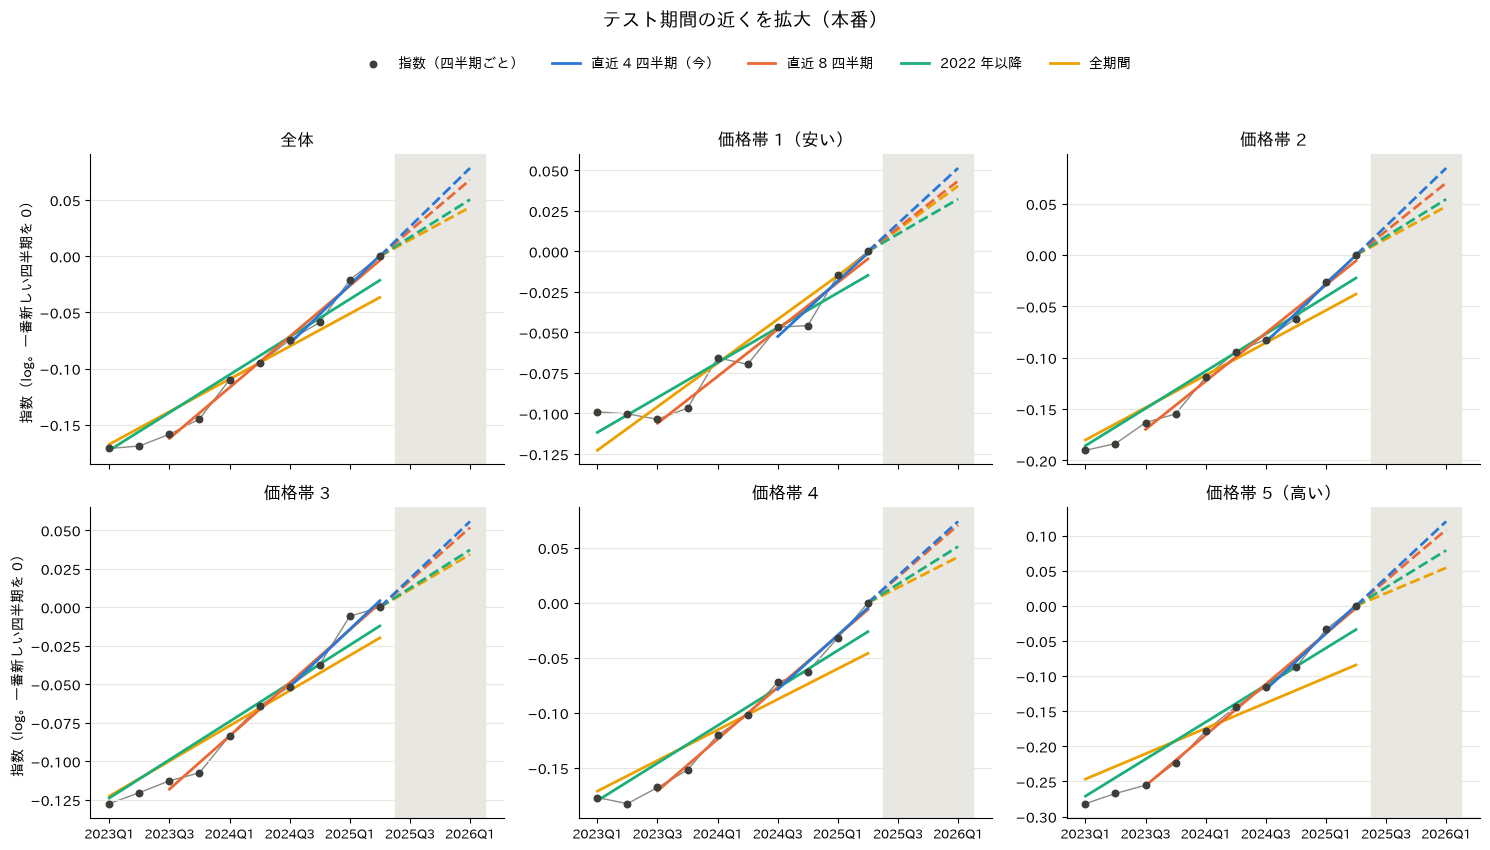

In [ ]:
draw(16, f"テスト期間の近くを拡大（{DATA}）")


## 傾きの表（年あたり log。0.10 ≒ +10%/年）

In [ ]:
slopes = {
    titles[g]: {
        name: np.polyfit(
            *(lambda p: (p.index, p.to_numpy()))(window_points(trend.level[g], w)), 1
        )[0]
        * 4
        for name, w in WINDOWS.items()
    }
    for g in groups
}
pd.DataFrame(slopes).T.round(3)


,直近 4 四半期（今）,直近 8 四半期,2022 年以降,全期間
全体,0.105,0.091,0.067,0.058
価格帯 1（安い）,0.069,0.058,0.043,0.054
価格帯 2,0.113,0.094,0.073,0.063
価格帯 3,0.074,0.069,0.050,0.046
価格帯 4,0.099,0.094,0.068,0.056
価格帯 5（高い）,0.160,0.145,0.105,0.072


## 読み方のメモ

- 破線の終わり（2026Q1）の高さが、テスト期間の最後で足し戻す指数。期間によって、ここが大きく変わる
- 直近 4 四半期は点が 4 つだけなので、1 つの四半期のぶれで傾きが大きく変わる
- 全期間の直線は、上がり方の遅かった 2019〜2021 年に引っ張られる